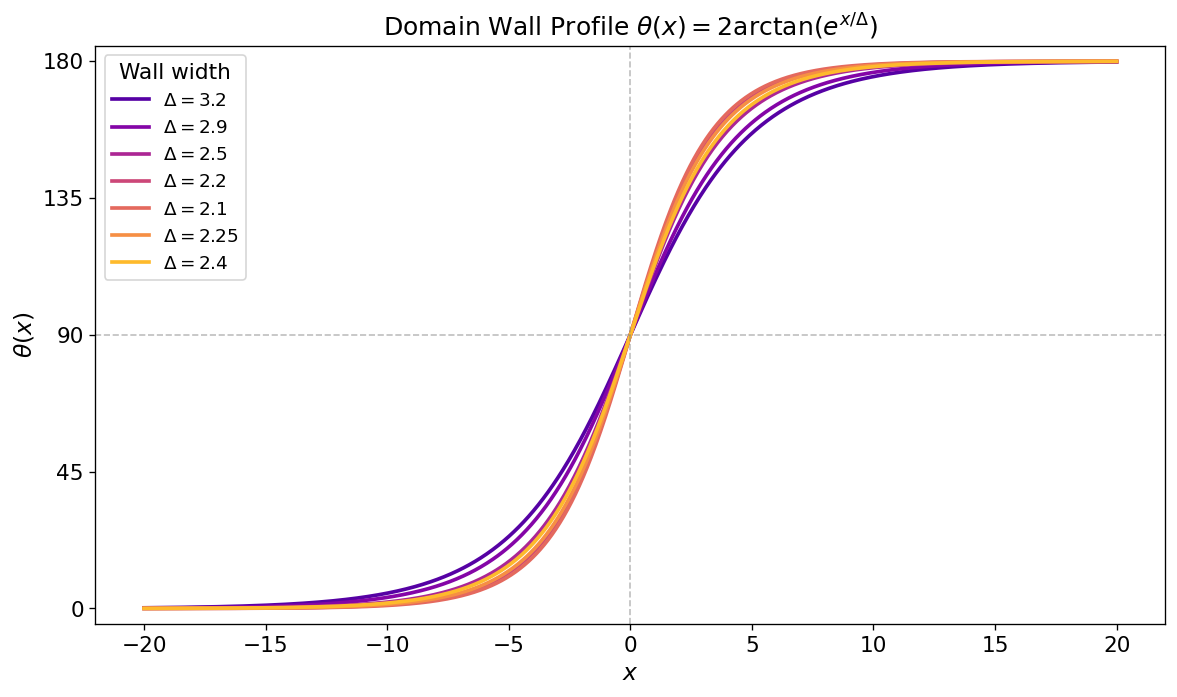

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from ipywidgets import interact, FloatSlider, FloatLogSlider
import warnings
warnings.filterwarnings('ignore')

# Set up nice plotting defaults
plt.rcParams.update({
    'font.size': 13,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'legend.fontsize': 11,
    'figure.dpi': 120,
    'lines.linewidth': 2.2,
    'axes.grid': False,
    'grid.alpha': 0.3,
})

# =============================================================================
# Part 1: Static plots showing wall profiles and symmetry properties
# =============================================================================

# Define the wall profile
def theta_profile(x, delta):
    """Bloch/Neel/Hybrid wall profile: theta(x) = 2*arctan(exp(x/delta))"""
    return 2 * np.arctan(np.exp(x / delta))

def magnetization_components(x, delta, psi):
    """
    Compute Mx, My, Mz for a domain wall with:
      - wall normal along x
      - easy axis along z
      - azimuthal angle psi (psi=0: Neel, psi=pi/2: Bloch)
    Returns normalized components (M/Ms).
    """
    theta = theta_profile(x, delta)
    Mx = np.sin(theta) * np.cos(psi)
    My = np.sin(theta) * np.sin(psi)
    Mz = np.cos(theta)
    return Mx, My, Mz

# Spatial grid
x = np.linspace(-20, 20, 1000)

# --- Figure 1: theta(x) for different delta values ---
fig1, ax1 = plt.subplots(figsize=(10, 6))

deltas = [3.2, 2.9, 2.5, 2.2, 2.1, 2.25, 2.4]
colors_delta = plt.cm.plasma(np.linspace(0.15, 0.85, len(deltas)))

for delta, color in zip(deltas, colors_delta):
    theta = theta_profile(x, delta)
    ax1.plot(x, np.degrees(theta), color=color, label=rf'$\Delta = {delta}$')

ax1.axhline(90, color='gray', ls='--', alpha=0.5, lw=1)
ax1.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)
ax1.set_xlabel(r'$x$')
ax1.set_ylabel(r'$\theta(x)$')
ax1.set_title(r'Domain Wall Profile $\theta(x) = 2\arctan(e^{x/\Delta})$')
ax1.legend(title='Wall width')
ax1.set_ylim(-5, 185)
ax1.set_yticks([0, 45, 90, 135, 180])
plt.tight_layout()
plt.show()



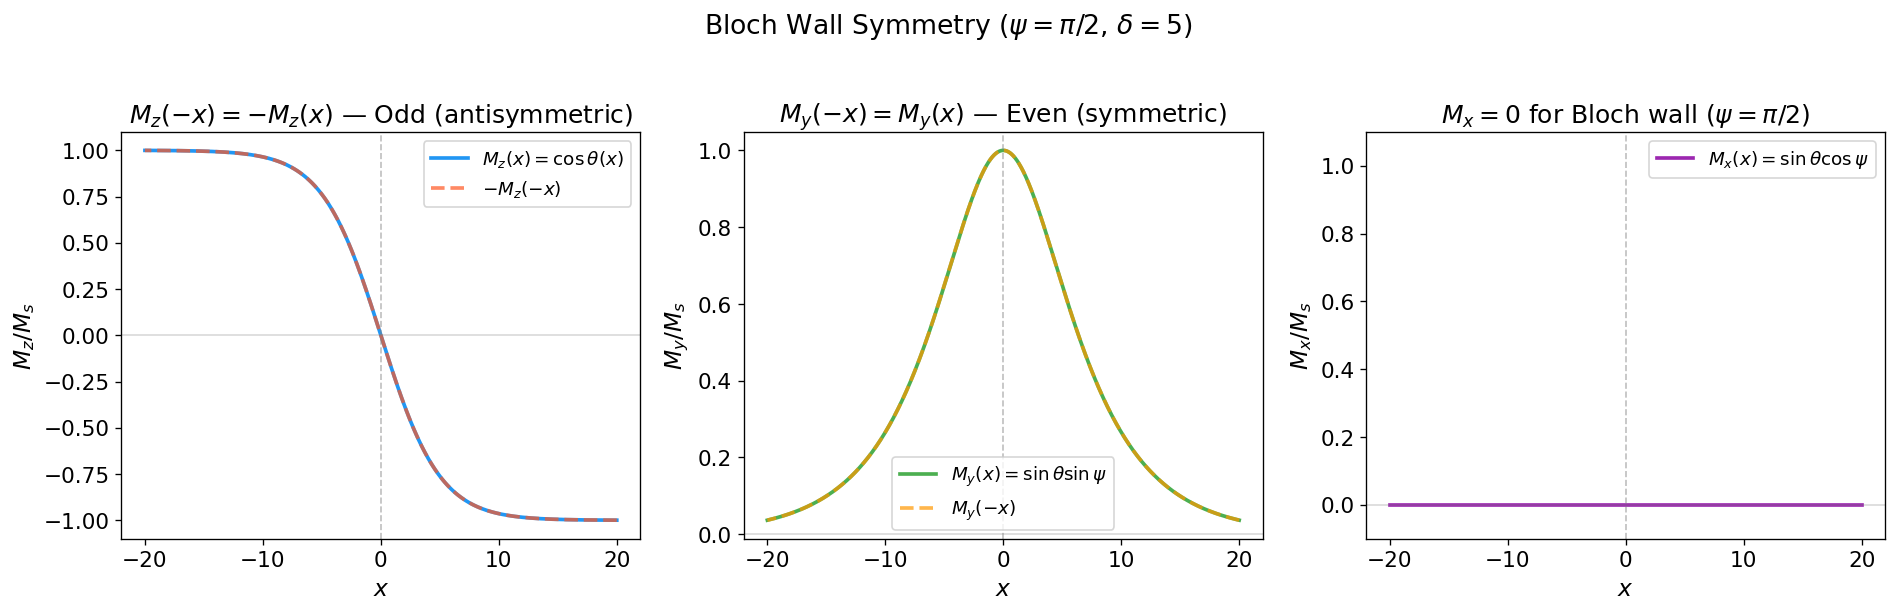

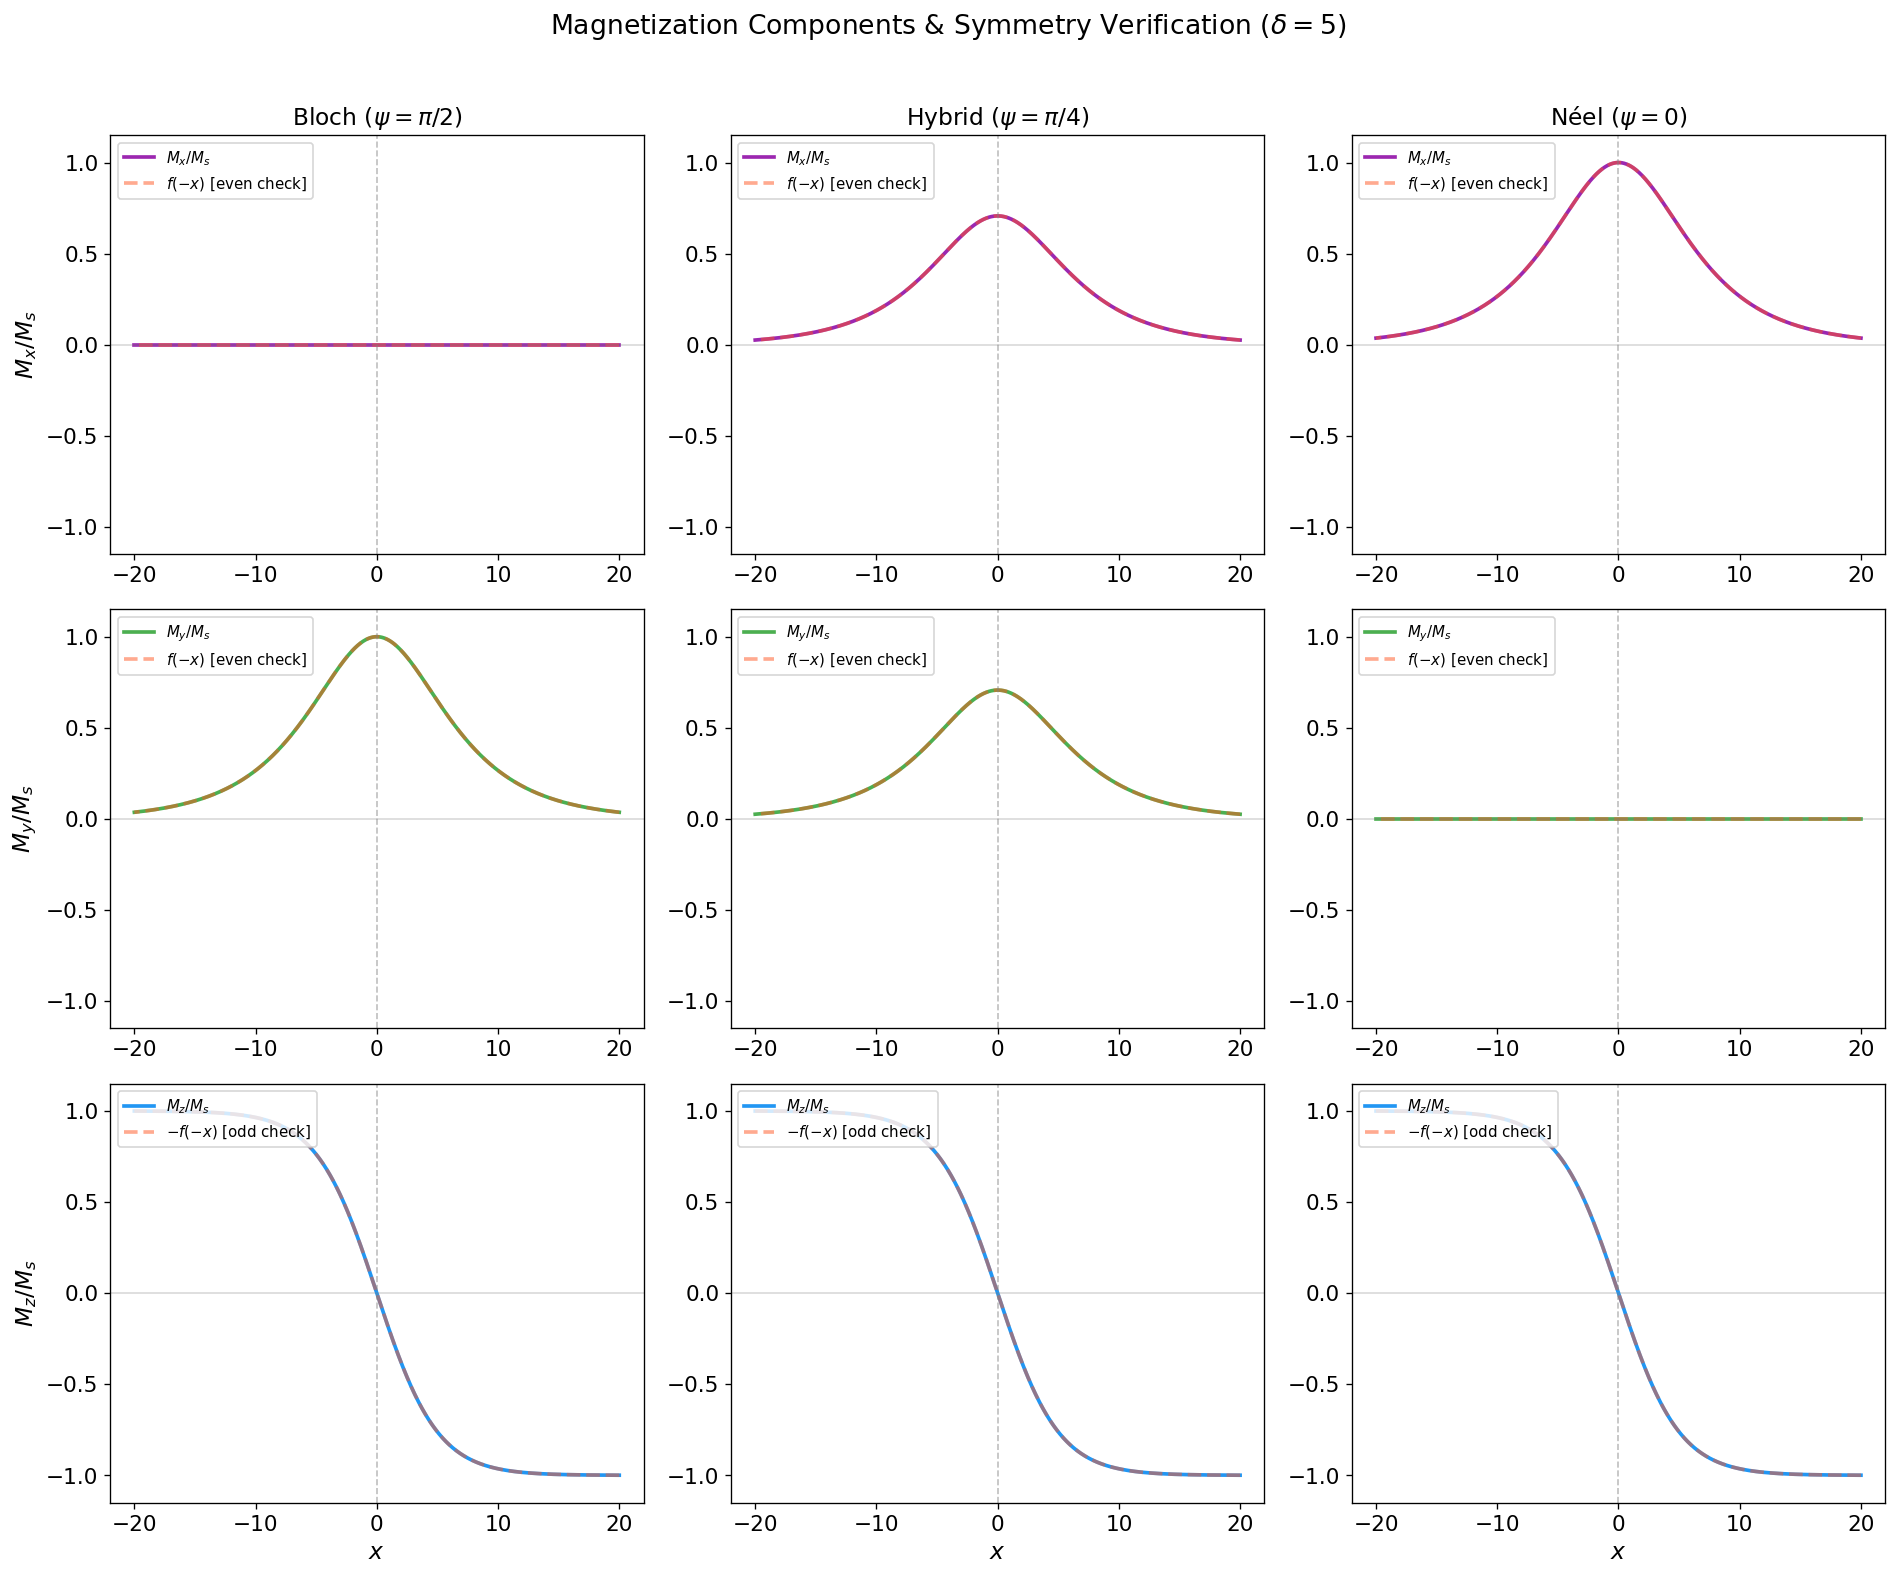

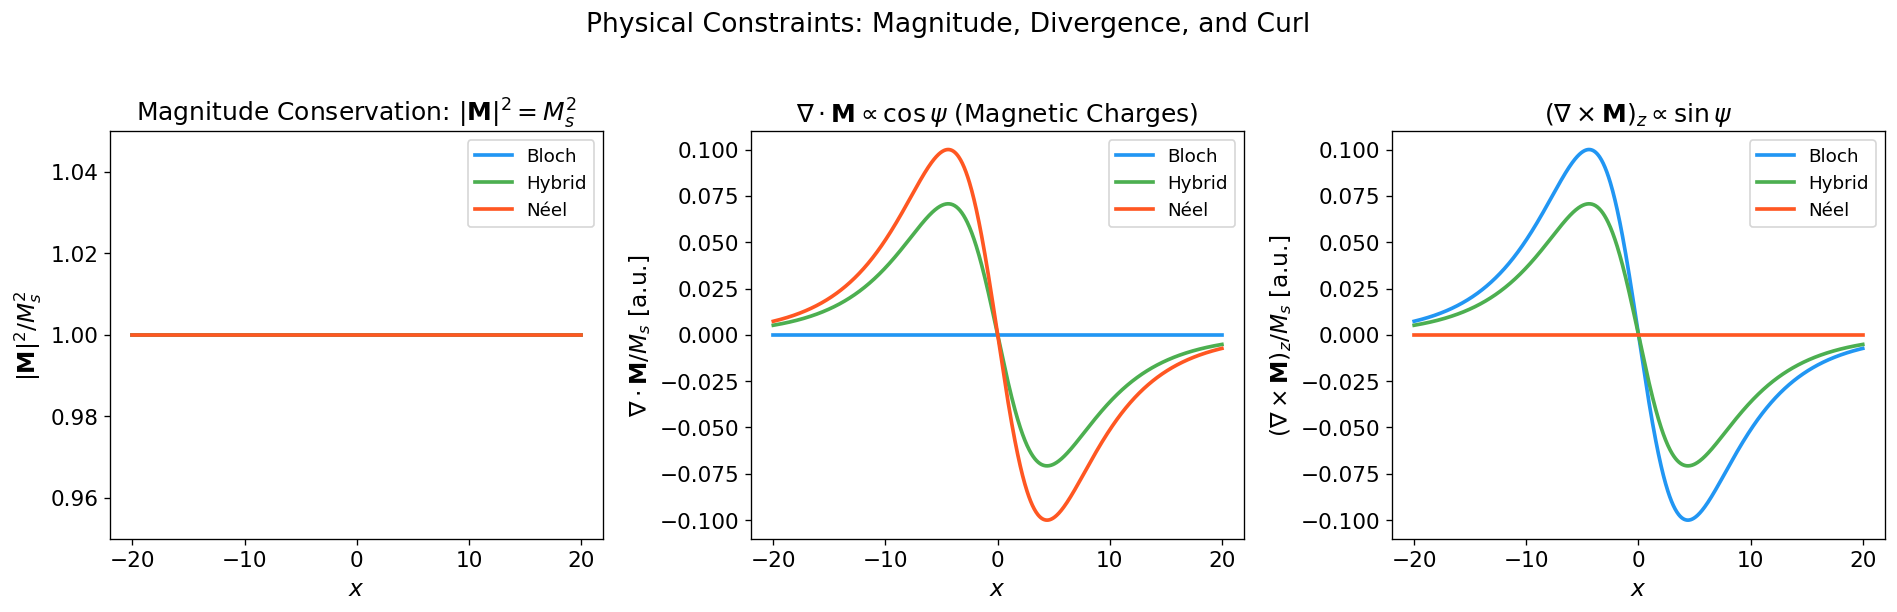

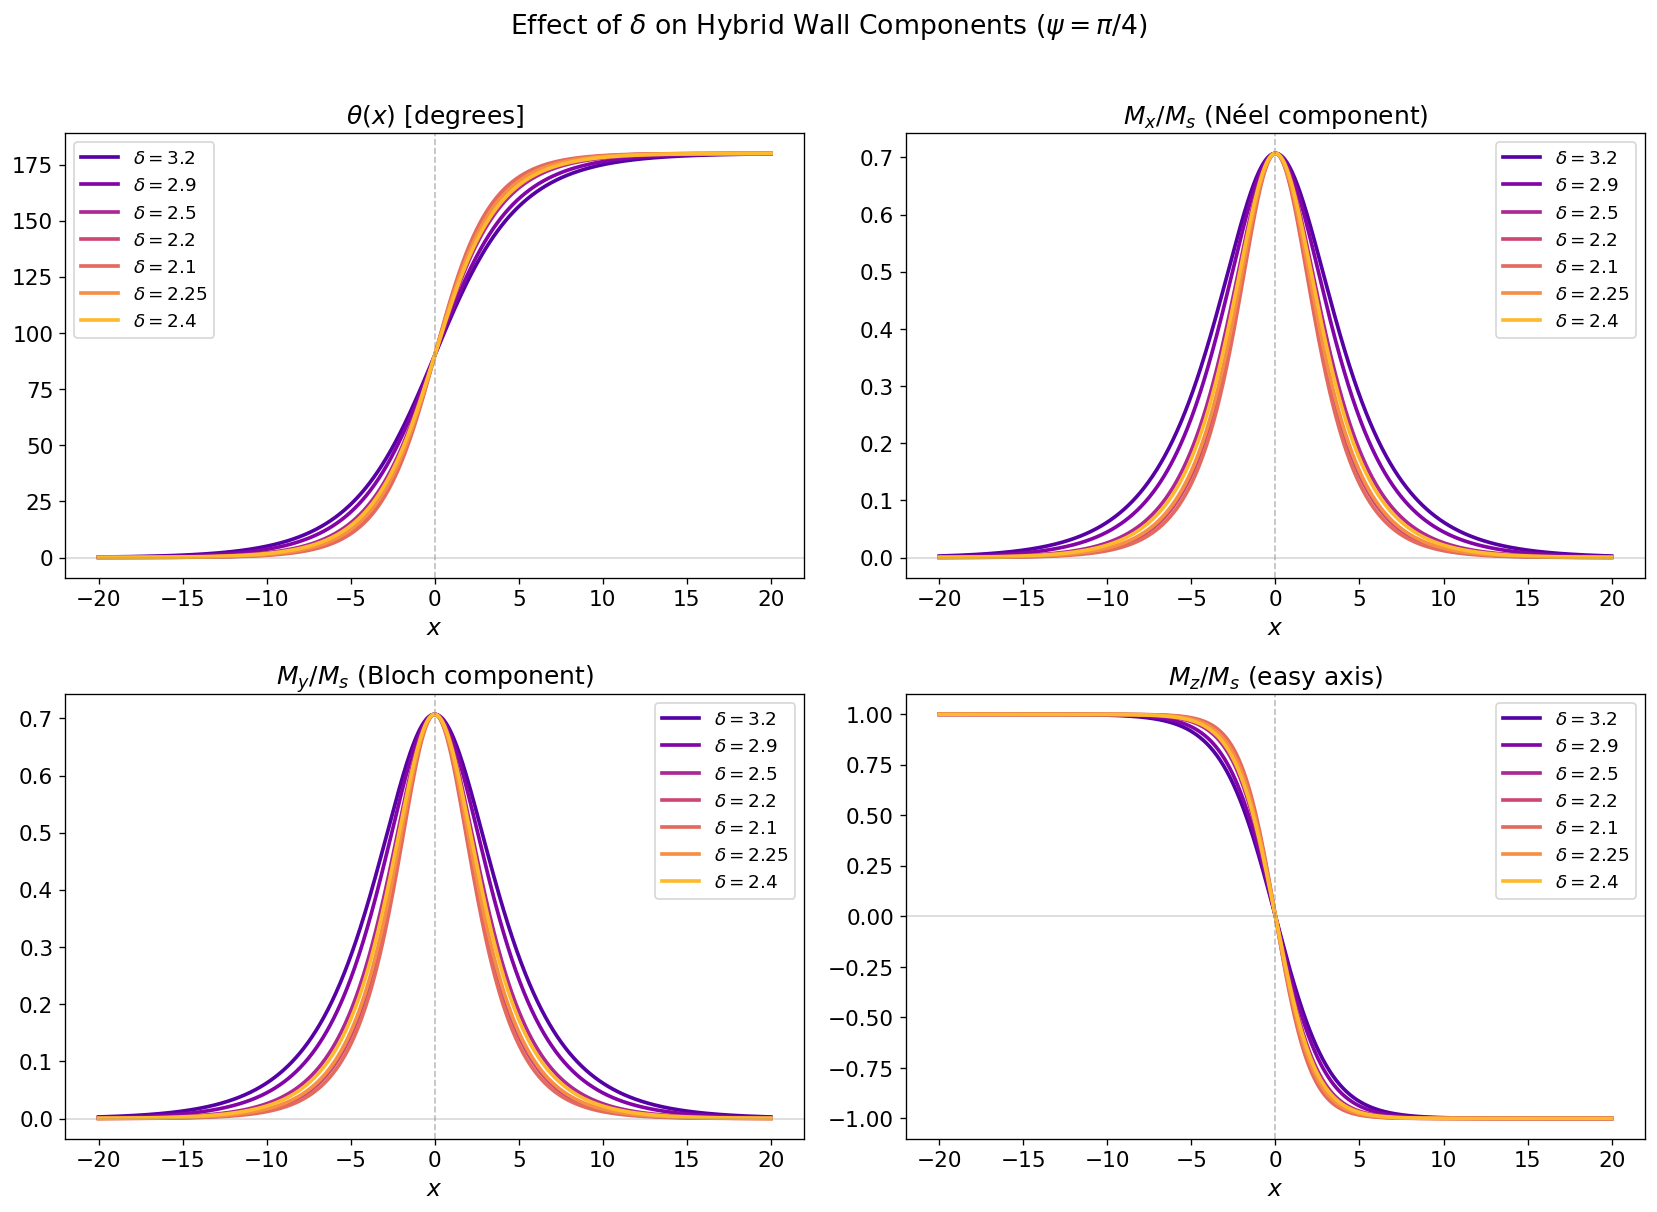

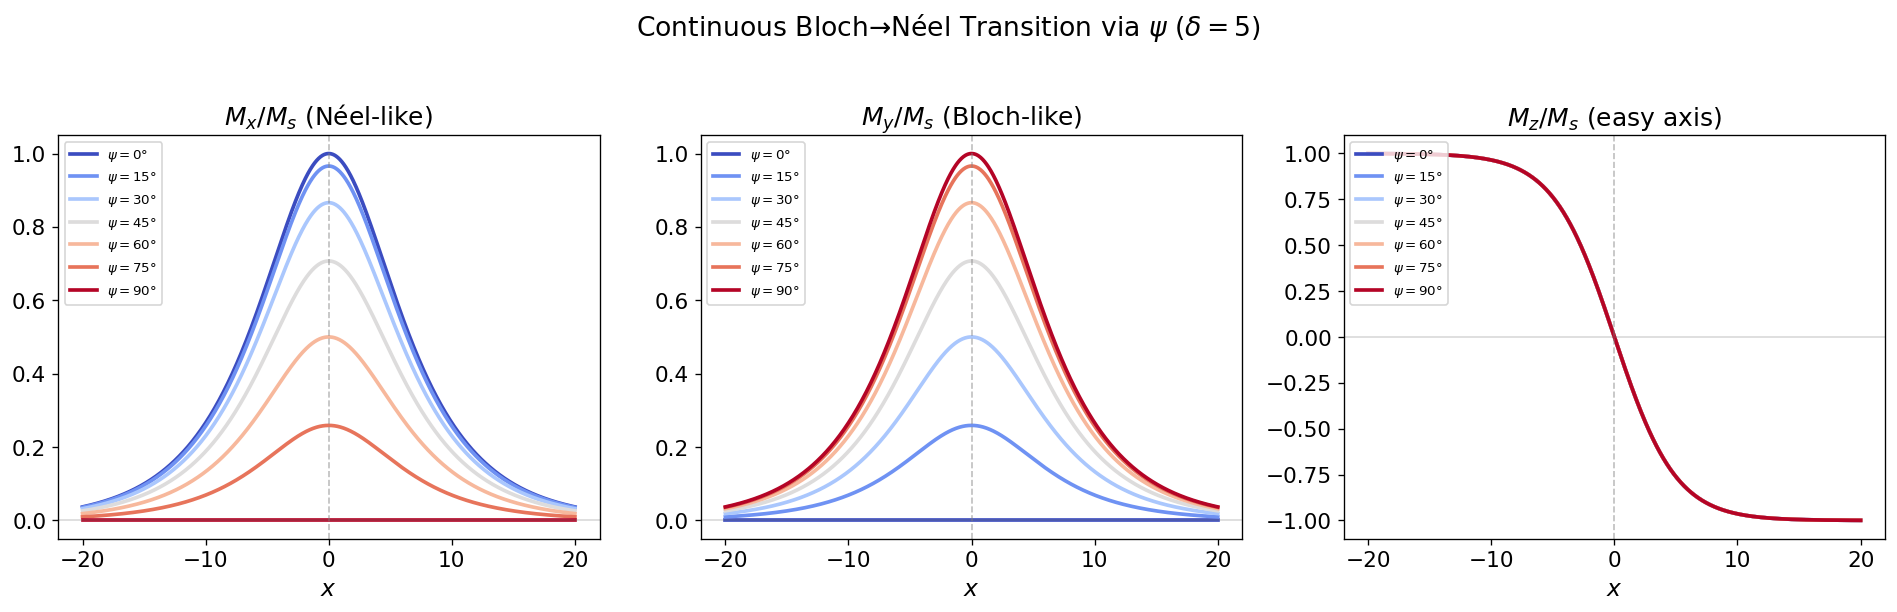

SYMMETRY SUMMARY

For a 180° domain wall centered at x=0 with profile θ(x) = 2·arctan(exp(x/δ)):

  θ(-x) = π - θ(x)

This implies:
  • cos θ(-x) = -cos θ(x)  →  Mz is ODD  (antisymmetric)
  • sin θ(-x) = +sin θ(x)  →  Mx, My are EVEN (symmetric)

These symmetries hold for ALL values of δ and ψ.

Key reconstruction constraints:
  1. |M|² = Ms²  everywhere (magnitude conservation)
  2. ∫(dθ/dx)dx = π  (topological winding)
  3. Mz is odd, Mx/My are even about wall center
  4. ∇·M ∝ cos ψ  (only Néel component creates charges)
  5. (∇×M)_z ∝ sin ψ  (Bloch component is solenoidal)
  6. ψ fixed by DMI chirality (global constraint)



In [9]:
# --- Figure 2: Symmetry demonstration for a Bloch wall ---
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 5))

delta_demo = 5
psi_bloch = np.pi / 2  # Bloch wall

Mx_b, My_b, Mz_b = magnetization_components(x, delta_demo, psi_bloch)

# Mz: odd symmetry
ax = axes2[0]
ax.plot(x, Mz_b, color='#2196F3', label=r'$M_z(x) = \cos\theta(x)$')
ax.plot(-x, -Mz_b, '--', color='#FF5722', alpha=0.7, label=r'$-M_z(-x)$')
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$M_z / M_s$')
ax.set_title(r'$M_z(-x) = -M_z(x)$ — Odd (antisymmetric)')
ax.legend()
ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)

# My: even symmetry (Bloch component)
ax = axes2[1]
ax.plot(x, My_b, color='#4CAF50', label=r'$M_y(x) = \sin\theta\sin\psi$')
ax.plot(-x, My_b, '--', color='#FF9800', alpha=0.7, label=r'$M_y(-x)$')
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$M_y / M_s$')
ax.set_title(r'$M_y(-x) = M_y(x)$ — Even (symmetric)')
ax.legend()
ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)

# Mx: even symmetry (zero for Bloch, but show structure)
ax = axes2[2]
ax.plot(x, Mx_b, color='#9C27B0', label=r'$M_x(x) = \sin\theta\cos\psi$')
ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$M_x / M_s$')
ax.set_title(r'$M_x = 0$ for Bloch wall ($\psi=\pi/2$)')
ax.legend()
ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)
ax.set_ylim(-0.1, 1.1)

fig2.suptitle(rf'Bloch Wall Symmetry ($\psi = \pi/2$, $\delta = {delta_demo}$)', 
              fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# --- Figure 3: Comparison of Bloch, Neel, and Hybrid walls ---
fig3, axes3 = plt.subplots(3, 3, figsize=(16, 13))

wall_types = [
    (r'Bloch ($\psi = \pi/2$)', np.pi/2),
    (r'Hybrid ($\psi = \pi/4$)', np.pi/4),
    (r'Néel ($\psi = 0$)', 0.0),
]

comp_labels = [r'$M_x/M_s$', r'$M_y/M_s$', r'$M_z/M_s$']
comp_colors = ['#9C27B0', '#4CAF50', '#2196F3']

for col, (wall_name, psi_val) in enumerate(wall_types):
    Mx, My, Mz = magnetization_components(x, delta_demo, psi_val)
    components = [Mx, My, Mz]
    
    for row, (comp, label, color) in enumerate(zip(components, comp_labels, comp_colors)):
        ax = axes3[row, col]
        ax.plot(x, comp, color=color, label=label)
        
        # Show symmetry verification
        if row < 2:  # Mx, My are even
            ax.plot(-x, comp, '--', color='#FF5722', alpha=0.5, 
                    label=r'$f(-x)$ [even check]')
        else:  # Mz is odd
            ax.plot(-x, -comp, '--', color='#FF5722', alpha=0.5, 
                    label=r'$-f(-x)$ [odd check]')
        
        ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
        ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)
        ax.legend(loc='upper left', fontsize=9)
        ax.set_ylim(-1.15, 1.15)
        
        if row == 0:
            ax.set_title(wall_name, fontsize=14)
        if row == 2:
            ax.set_xlabel(r'$x$')
        if col == 0:
            ax.set_ylabel(label)

fig3.suptitle(rf'Magnetization Components & Symmetry Verification ($\delta = {delta_demo}$)', 
              fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# --- Figure 4: |M| conservation check and divergence/curl ---
fig4, axes4 = plt.subplots(1, 3, figsize=(16, 5))

for wall_name, psi_val, color in zip(
    ['Bloch', 'Hybrid', 'Néel'],
    [np.pi/2, np.pi/4, 0.0],
    ['#2196F3', '#4CAF50', '#FF5722']
):
    Mx, My, Mz = magnetization_components(x, delta_demo, psi_val)
    
    # |M|^2 check
    Msq = Mx**2 + My**2 + Mz**2
    axes4[0].plot(x, Msq, color=color, label=wall_name)
    
    # Divergence: div M = cos(psi) * cos(theta) * dtheta/dx
    theta = theta_profile(x, delta_demo)
    dthetadx = np.sin(theta) / delta_demo
    div_M = np.cos(psi_val) * np.cos(theta) * dthetadx
    axes4[1].plot(x, div_M, color=color, label=wall_name)
    
    # Curl z-component: sin(psi) * cos(theta) * dtheta/dx
    curl_Mz = np.sin(psi_val) * np.cos(theta) * dthetadx
    axes4[2].plot(x, curl_Mz, color=color, label=wall_name)

axes4[0].set_xlabel(r'$x$')
axes4[0].set_ylabel(r'$|\mathbf{M}|^2 / M_s^2$')
axes4[0].set_title(r'Magnitude Conservation: $|\mathbf{M}|^2 = M_s^2$')
axes4[0].legend()
axes4[0].set_ylim(0.95, 1.05)

axes4[1].set_xlabel(r'$x$')
axes4[1].set_ylabel(r'$\nabla \cdot \mathbf{M} / M_s$ [a.u.]')
axes4[1].set_title(r'$\nabla \cdot \mathbf{M} \propto \cos\psi$ (Magnetic Charges)')
axes4[1].legend()

axes4[2].set_xlabel(r'$x$')
axes4[2].set_ylabel(r'$(\nabla \times \mathbf{M})_z / M_s$ [a.u.]')
axes4[2].set_title(r'$(\nabla \times \mathbf{M})_z \propto \sin\psi$')
axes4[2].legend()

fig4.suptitle('Physical Constraints: Magnitude, Divergence, and Curl', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# --- Figure 5: Effect of delta on all components (hybrid wall) ---
fig5, axes5 = plt.subplots(2, 2, figsize=(14, 10))

psi_hybrid = np.pi / 4  # 45-degree hybrid wall

for delta, color in zip(deltas, colors_delta):
    theta = theta_profile(x, delta)
    Mx, My, Mz = magnetization_components(x, delta, psi_hybrid)
    
    axes5[0, 0].plot(x, np.degrees(theta), color=color, label=rf'$\delta={delta}$')
    axes5[0, 1].plot(x, Mx, color=color, label=rf'$\delta={delta}$')
    axes5[1, 0].plot(x, My, color=color, label=rf'$\delta={delta}$')
    axes5[1, 1].plot(x, Mz, color=color, label=rf'$\delta={delta}$')

titles = [r'$\theta(x)$ [degrees]', r'$M_x/M_s$ (Néel component)', 
          r'$M_y/M_s$ (Bloch component)', r'$M_z/M_s$ (easy axis)']

for ax, title in zip(axes5.flat, titles):
    ax.set_xlabel(r'$x$')
    ax.set_title(title)
    ax.legend()
    ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
    ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)

fig5.suptitle(r'Effect of $\delta$ on Hybrid Wall Components ($\psi = \pi/4$)', 
              fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# --- Figure 6: Psi sweep showing continuous transition ---
fig6, axes6 = plt.subplots(1, 3, figsize=(16, 5))

psi_values = np.linspace(0, np.pi/2, 7)
colors_psi = plt.cm.coolwarm(np.linspace(0, 1, len(psi_values)))

for psi_val, color in zip(psi_values, colors_psi):
    Mx, My, Mz = magnetization_components(x, delta_demo, psi_val)
    label = rf'$\psi = {np.degrees(psi_val):.0f}°$'
    axes6[0].plot(x, Mx, color=color, label=label)
    axes6[1].plot(x, My, color=color, label=label)
    axes6[2].plot(x, Mz, color=color, label=label)

axes6[0].set_title(r'$M_x/M_s$ (Néel-like)')
axes6[1].set_title(r'$M_y/M_s$ (Bloch-like)')
axes6[2].set_title(r'$M_z/M_s$ (easy axis)')

for ax in axes6:
    ax.set_xlabel(r'$x$')
    ax.legend(fontsize=8, loc='upper left')
    ax.axhline(0, color='gray', ls='-', alpha=0.3, lw=1)
    ax.axvline(0, color='gray', ls='--', alpha=0.5, lw=1)

fig6.suptitle(rf'Continuous Bloch→Néel Transition via $\psi$ ($\delta = {delta_demo}$)', 
              fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

print("="*70)
print("SYMMETRY SUMMARY")
print("="*70)
print("""
For a 180° domain wall centered at x=0 with profile θ(x) = 2·arctan(exp(x/δ)):

  θ(-x) = π - θ(x)

This implies:
  • cos θ(-x) = -cos θ(x)  →  Mz is ODD  (antisymmetric)
  • sin θ(-x) = +sin θ(x)  →  Mx, My are EVEN (symmetric)

These symmetries hold for ALL values of δ and ψ.

Key reconstruction constraints:
  1. |M|² = Ms²  everywhere (magnitude conservation)
  2. ∫(dθ/dx)dx = π  (topological winding)
  3. Mz is odd, Mx/My are even about wall center
  4. ∇·M ∝ cos ψ  (only Néel component creates charges)
  5. (∇×M)_z ∝ sin ψ  (Bloch component is solenoidal)
  6. ψ fixed by DMI chirality (global constraint)
""")